# Exploring Coeliac TCRs

Looking at the sequences of the TCRs reacting to specific coeliac antigens.

In [1]:
import subprocess

import logomaker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from sklearn.cluster import AgglomerativeClustering

from tcr_pmhc_predicted_structures.clustering import calculate_sequence_distances

In [2]:
CLIP_DISTANCE = 5
MIN_CLUSTER_SIZE = 4

In [3]:
def align_sequences(sequences: list[str]) -> list[str]:
    child = subprocess.Popen(
        [
            '/usr/bin/env',
            'mafft-linsi',
            '--quiet',
            '--op',
            '2',
            '--ep',
            '10',
            '--amino',
            '-',
        ],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
    )
    child.stdin.write('\n'.join(f'>{idx}\n{sequence}' for idx, sequence in enumerate(sequences)).encode())
    child_out = child.communicate()[0].decode('utf8')
    aligned_sequences = [line.strip() for line in child_out.split('\n') if line and not line.startswith('>')]
    child.stdin.close()

    return aligned_sequences


def make_logo_plot(cluster: pd.DataFrame) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(10, 5), gridspec_kw={'width_ratios': (1, 5, 1), 'wspace': 0.1}, sharey=True)
    fig.suptitle(f'Cluster {cluster.name}')

    for chain_type, axes_row in zip(('a', 'b'), axes, strict=True):
        axes_row[0].set_ylabel({'a': 'Alpha Chain', 'b': 'Beta Chain'}[chain_type], fontsize=14)

        aligned_sequences = align_sequences(cluster[f'cdr3{chain_type}'])
        probs = logomaker.alignment_to_matrix(aligned_sequences, to_type='counts')

        logomaker.Logo(probs, color_scheme='chemistry', show_spines=False, baseline_width=0.0, ax=axes_row[1])

        axes_row[1].set_xticks([])
        axes_row[1].set_yticks([])

        counts_v = cluster[f'v{chain_type}_gene'].value_counts()
        counts_j = cluster[f'j{chain_type}_gene'].value_counts()

        for ax, counts in zip([axes_row[0], axes_row[2]], [counts_v, counts_j], strict=True):
            previous_count = 0
            for gene_name, cum_count in counts.cumsum().items():
                logomaker.Glyph(0.5, gene_name[3:], previous_count, cum_count, ax=ax)
                previous_count = cum_count

            ax.set_xticks([])
            ax.set_yticks([])
            ax.spines[:].set_visible(False)


def plot_sequence_distances(
    distance_matrix: np.ndarray,
    cluster_colours: np.ndarray,
    cluster_order: np.ndarray,
    cluster_counts: np.ndarray,
    new_order: np.ndarray,
    subject_colours: np.ndarray,
    epitope_colours: np.ndarray | None = None,
    title: str | None = None,
) -> tuple[Figure, np.ndarray[Axes]]:
    if epitope_colours is not None:
        fig, axes = plt.subplots(1, 4, gridspec_kw={'width_ratios': [1, 1, 1, 20]})

    else:
        fig, axes = plt.subplots(1, 3, gridspec_kw={'width_ratios': [1, 1, 20]})

    if title:
        fig.suptitle(title)

    idx = 0

    axes[idx].imshow(subject_colours, aspect='auto')

    axes[idx].set_ylabel('Subject', fontsize=14)
    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    idx += 1

    if epitope_colours is not None:
        axes[idx].imshow(epitope_colours, aspect='auto')

        axes[idx].set_ylabel('Epitope', fontsize=14)
        axes[idx].set_xticks([])
        axes[idx].set_xticklabels('')
        axes[idx].set_yticks([])
        axes[idx].set_yticklabels('')

        idx += 1

    axes[idx].imshow(cluster_colours, aspect='auto')

    axes[idx].set_ylabel('Cluster', fontsize=14)
    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    accumulation = 0
    for cluster in cluster_order:
        cluster_size = cluster_counts[cluster]

        if cluster_size >= MIN_CLUSTER_SIZE:
            position = cluster_counts[cluster] // 2 + accumulation
            axes[idx].text(
                x=0.025,
                y=position,
                s=str(cluster),
                va='center',
                ha='center',
                fontsize=8,
            )

        accumulation += cluster_size

    idx += 1

    sns.heatmap(
        np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE),
        cmap='viridis_r',
        ax=axes[idx],
    )

    axes[idx].set_xlabel(r'CDR3$\alpha$', fontsize=14)
    axes[idx].set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
    axes[idx].yaxis.set_label_position('right')

    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    cbar = axes[idx].collections[0].colorbar
    cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
    cbar.set_ticks(cbar.get_ticks())
    cbar.set_ticklabels(
        [f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()]
    )

    fig.set_layout_engine('tight')

    return fig, axes

In [4]:
coeliac_sequences = pd.read_csv('../data/interim/sequences_coeliac.csv', index_col='id')

In [5]:
(
    coeliac_sequences.groupby('clone_id')['pmhc_calls']
    .apply(lambda antigens: '/'.join(sorted(set(antigens))))
    .value_counts()
)

pmhc_calls
a2       276
a1       157
w2       134
w1        66
a1/w1     42
Name: count, dtype: int64

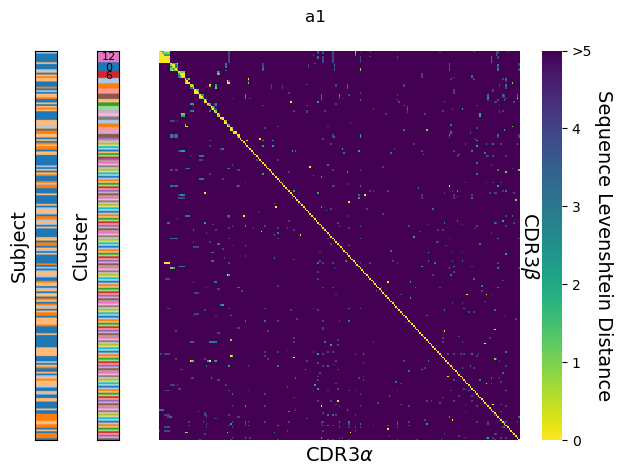

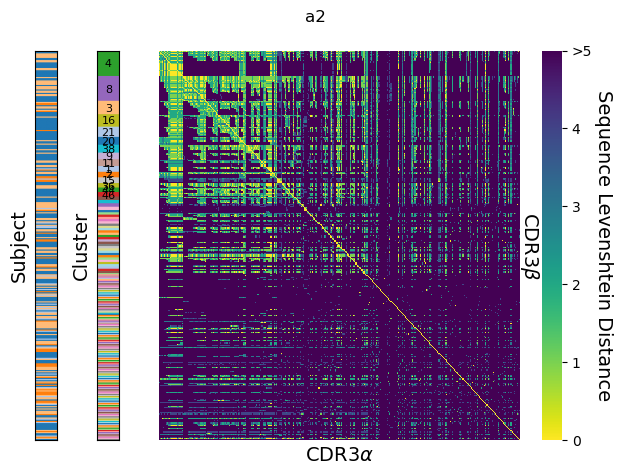

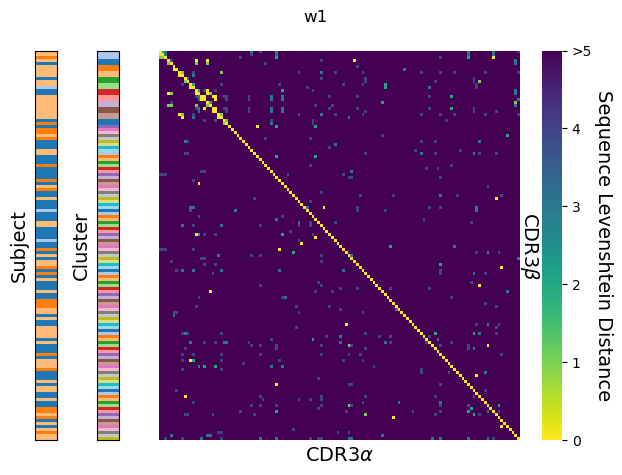

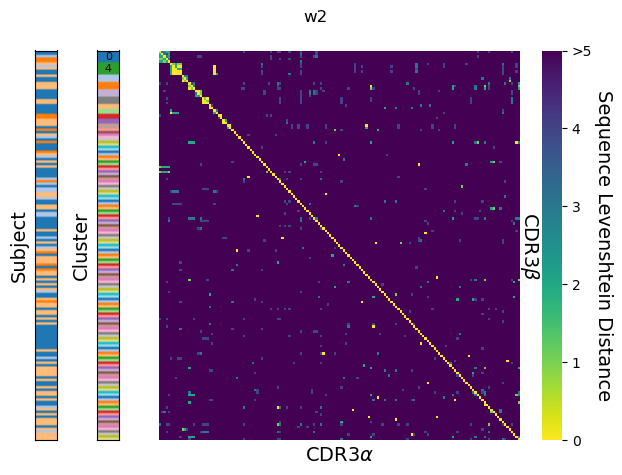

""


In [6]:
def _create_plot(group: pd.DataFrame) -> None:
    distance_matrix = calculate_sequence_distances(group['cdr3a'].tolist(), group['cdr3b'].tolist())
    cdr3_distance_matrix = distance_matrix + distance_matrix.T

    clusters = AgglomerativeClustering(
        n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
    ).fit_predict(cdr3_distance_matrix)

    cluster_counts = {}

    for cluster in clusters:
        if cluster not in cluster_counts:
            cluster_counts[cluster] = 1

        else:
            cluster_counts[cluster] += 1

    cluster_order = [
        cluster
        for cluster, _ in sorted(
            sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
        )
    ]

    new_order = []
    for cluster in cluster_order:
        (indices,) = np.where(clusters == cluster)
        new_order.extend(indices)

    new_order = np.array(new_order)

    unique_clusters = np.unique(clusters[new_order])

    palette = sns.color_palette('tab20')
    num_colours = len(palette)

    cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
    cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

    unique_subjects = sorted(group['donor_id'].unique())
    subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
    subject_colours = np.array([[subject_to_colour[subject]] for subject in group['donor_id'].to_numpy()[new_order]])

    plot_sequence_distances(
        distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours, title=group.name
    )
    plt.show()


coeliac_sequences.groupby('pmhc_calls').apply(_create_plot, include_groups=False)

In [7]:
def create_clusters(group: pd.DataFrame) -> pd.Series:
    distance_matrix = calculate_sequence_distances(group['cdr3a'].tolist(), group['cdr3b'].tolist())
    cdr3_distance_matrix = distance_matrix + distance_matrix.T

    clusters = AgglomerativeClustering(
        n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
    ).fit_predict(cdr3_distance_matrix)

    cluster_counts = {}

    for cluster in clusters:
        if cluster not in cluster_counts:
            cluster_counts[cluster] = 1

        else:
            cluster_counts[cluster] += 1

    clusters_filtered = pd.Series(
        [str(cluster) if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else 'None' for cluster in clusters],
        index=group.index,
        name='cluster',
    )

    return clusters_filtered


coeliac_sequences = coeliac_sequences.merge(
    coeliac_sequences.groupby('pmhc_calls')
    .apply(create_clusters, include_groups=False)
    .reset_index()
    .set_index('id')[['cluster']],
    how='left',
    left_index=True,
    right_index=True,
)

""


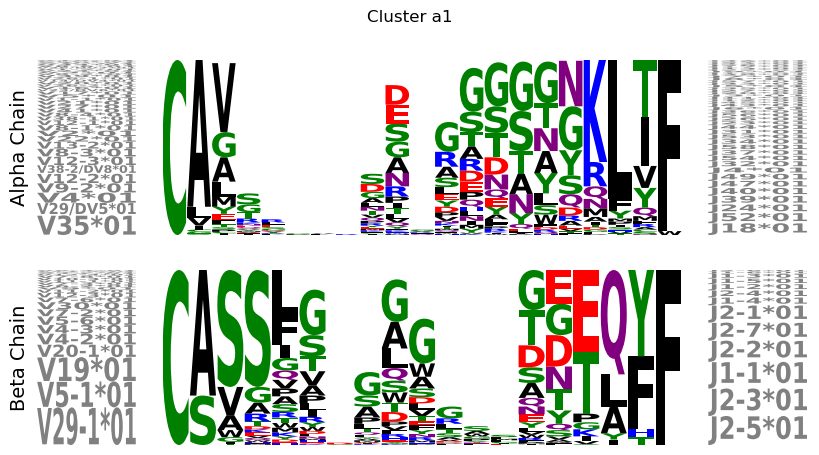

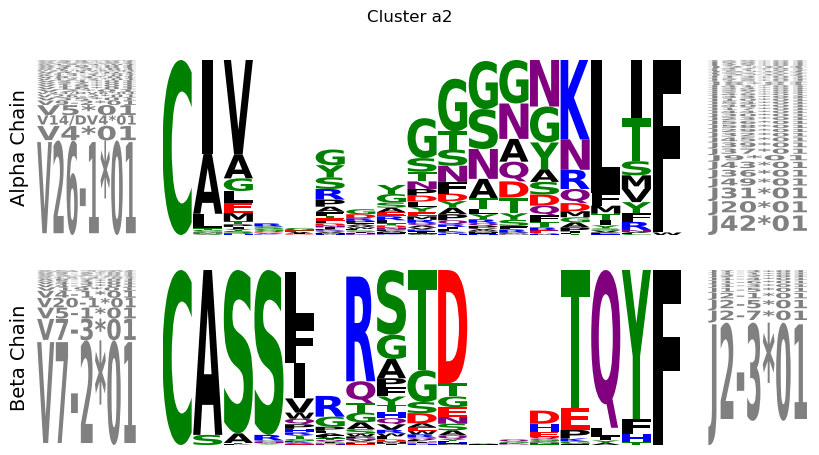

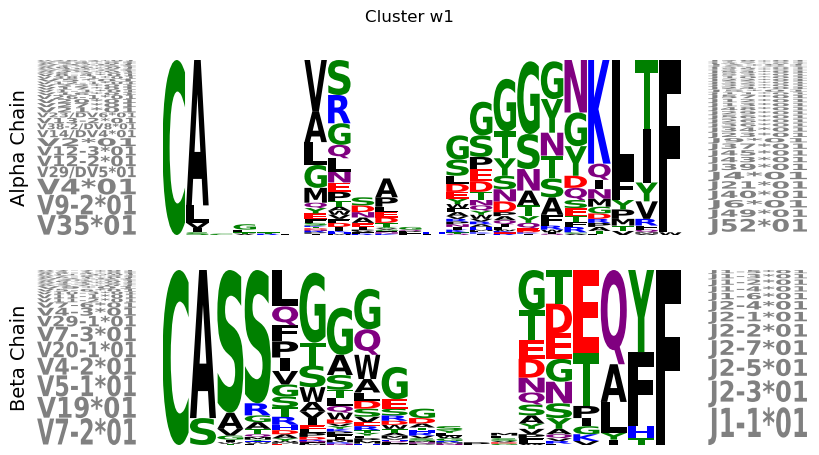

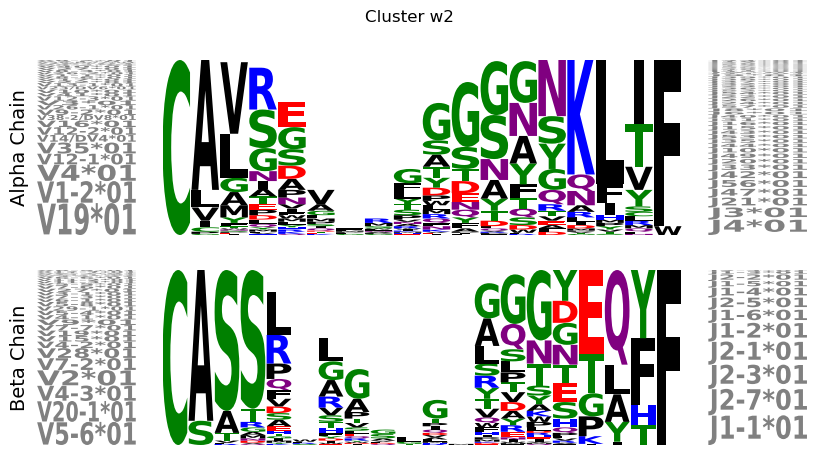

In [8]:
(coeliac_sequences.groupby(['pmhc_calls']).apply(make_logo_plot, include_groups=False))

""


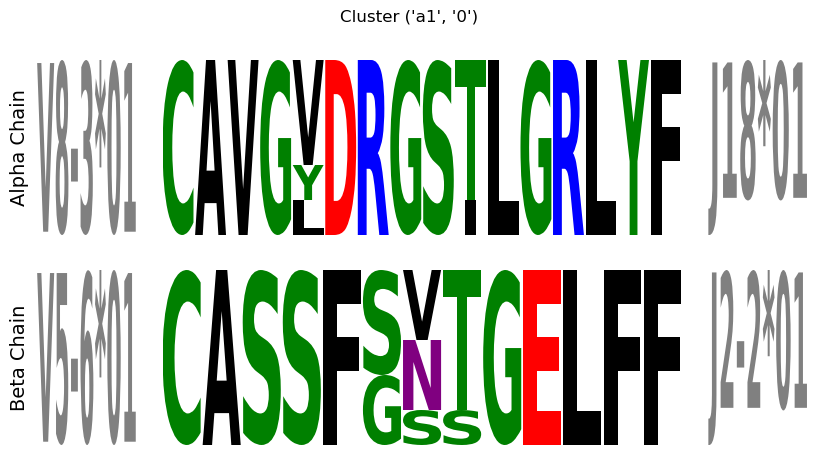

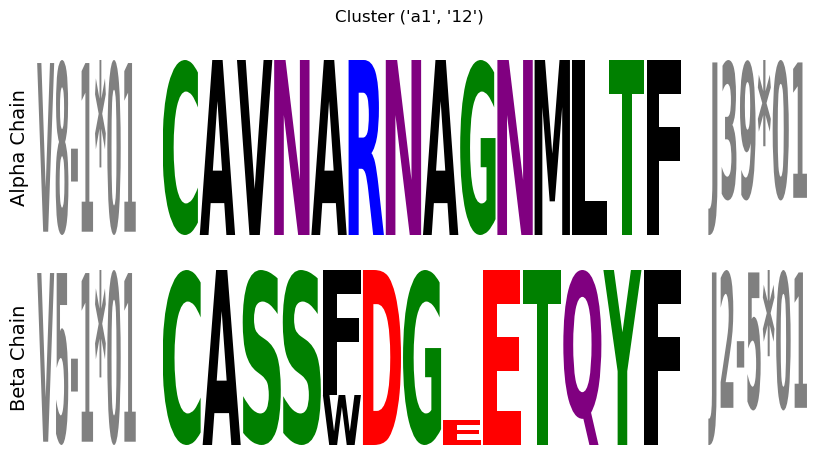

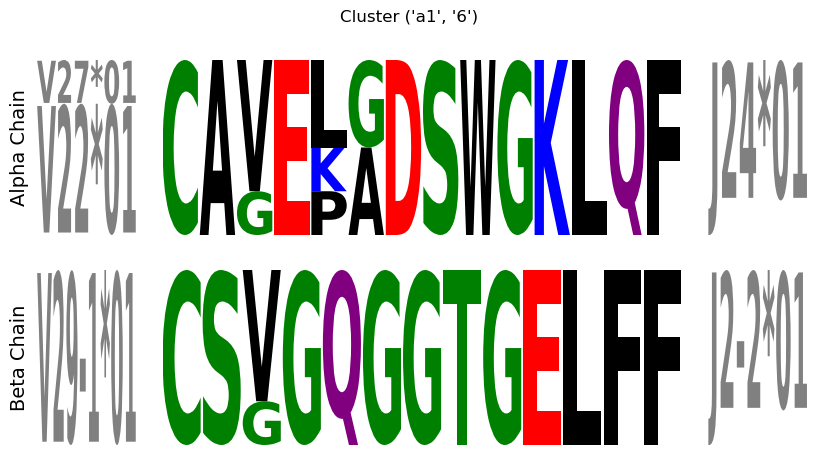

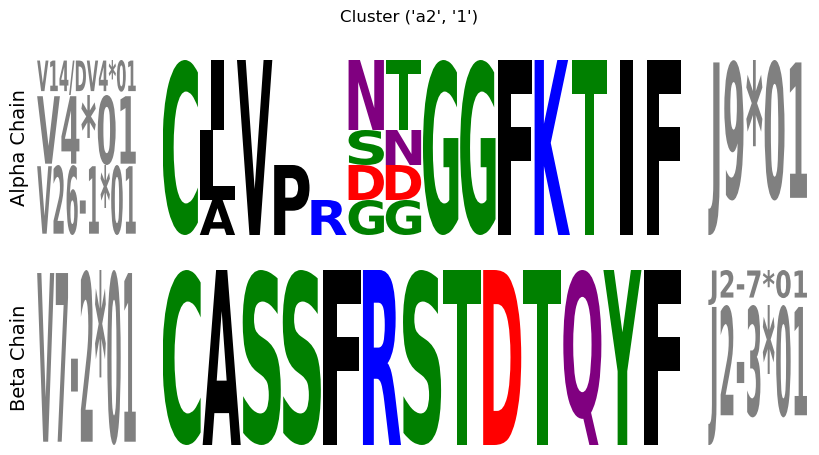

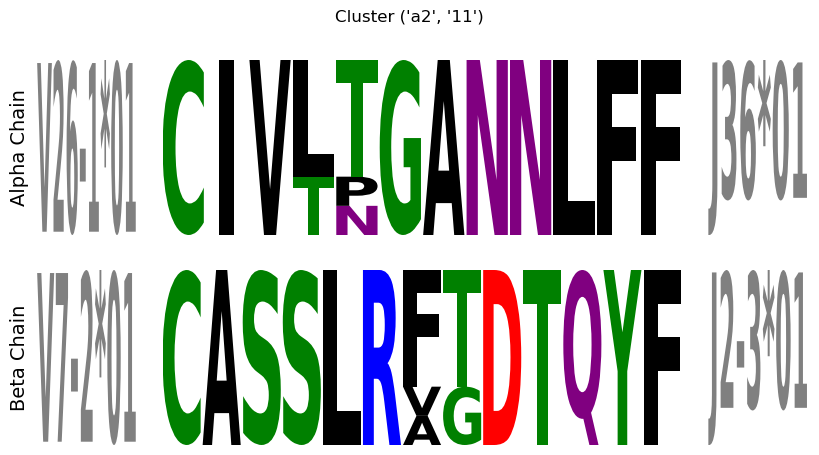

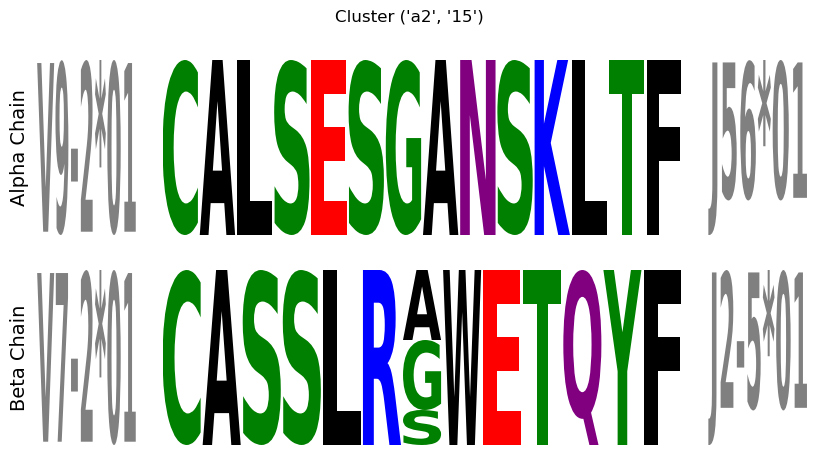

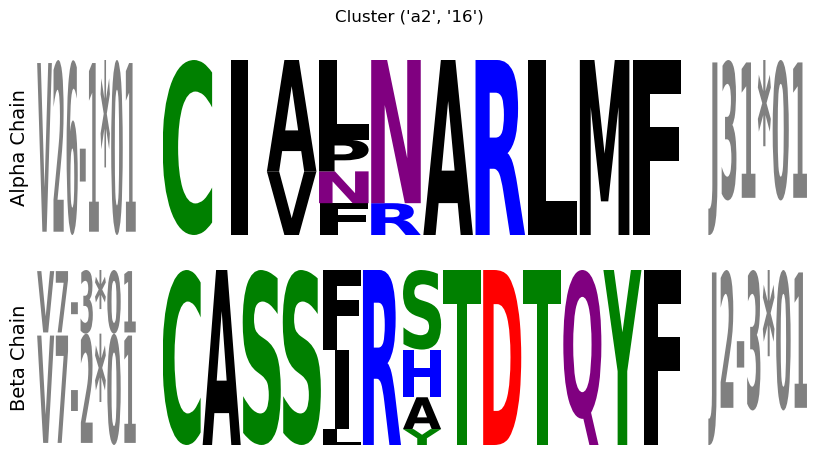

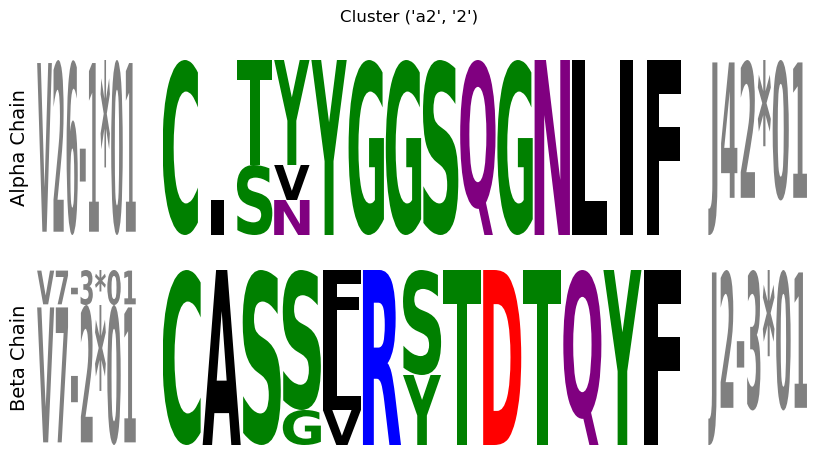

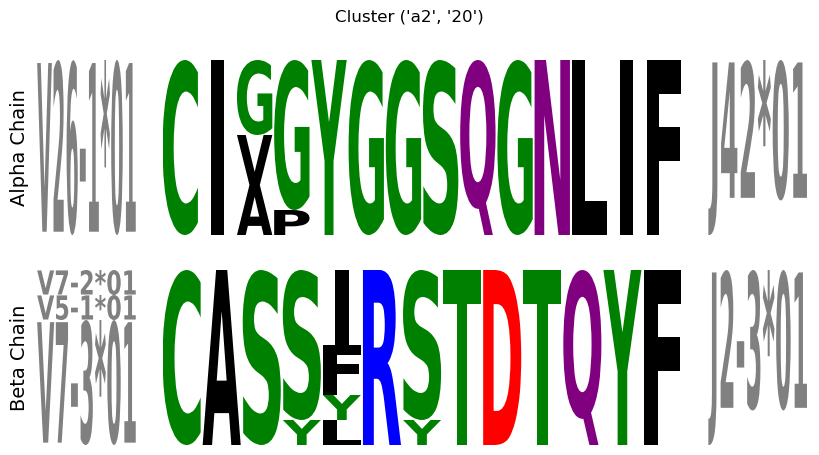

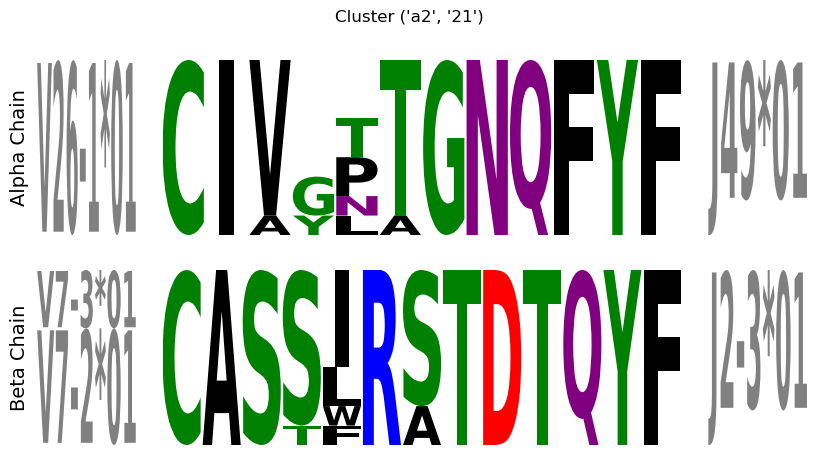

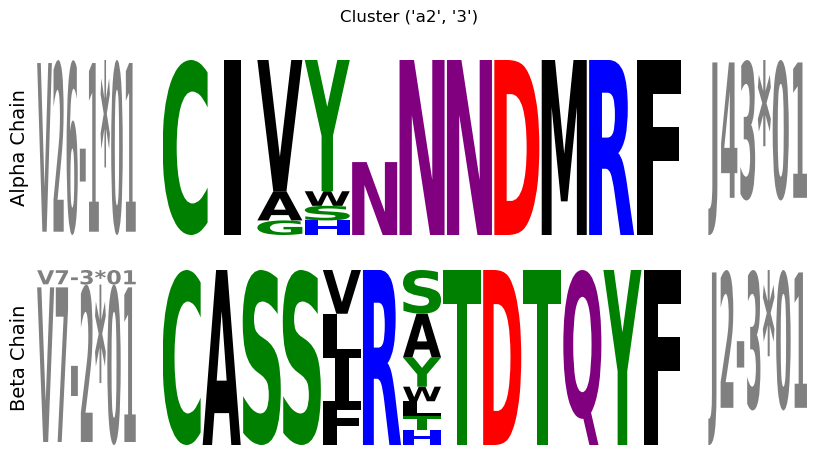

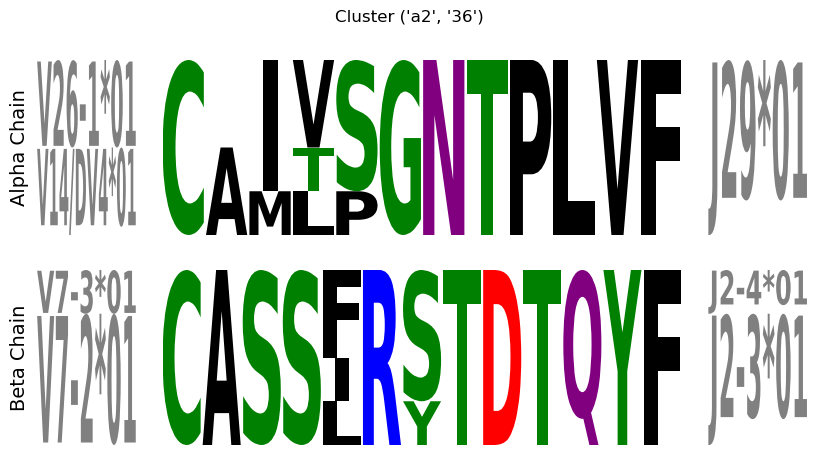

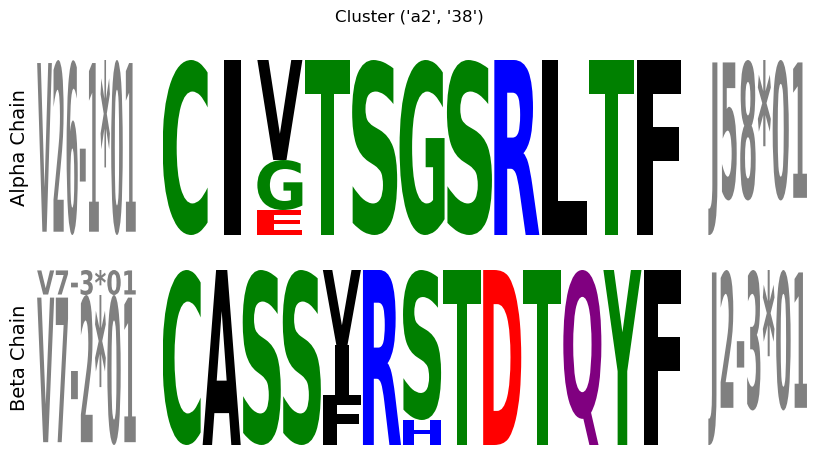

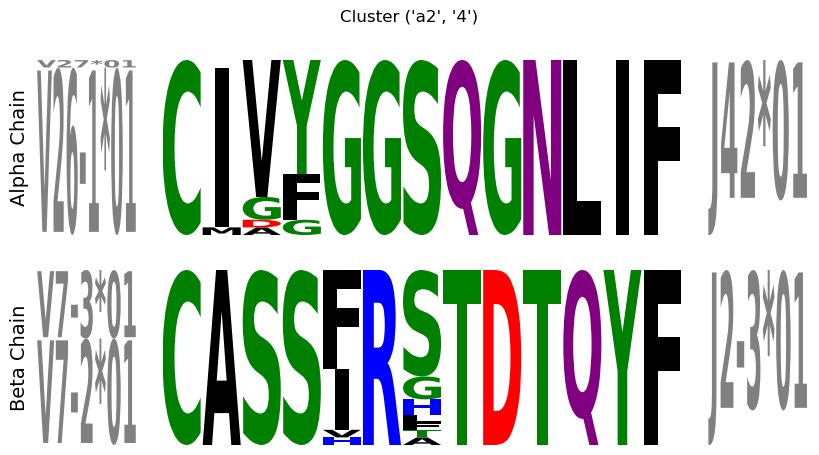

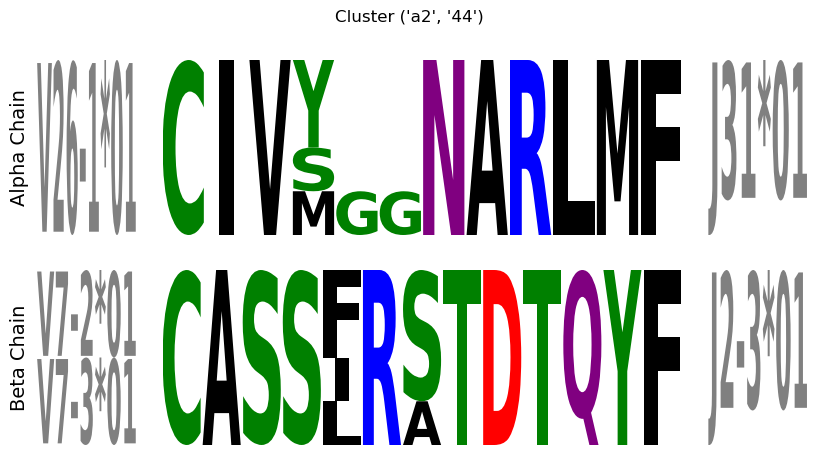

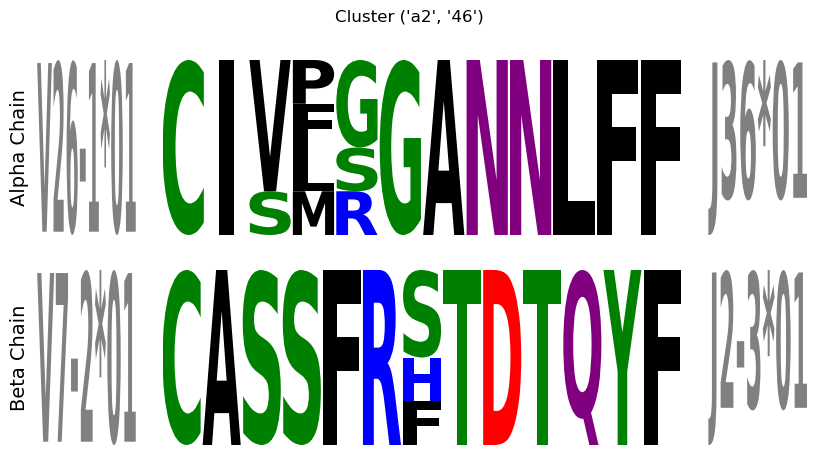

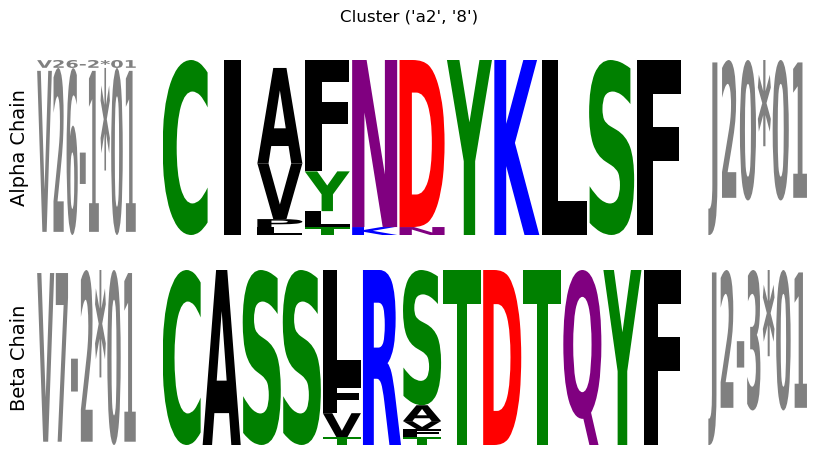

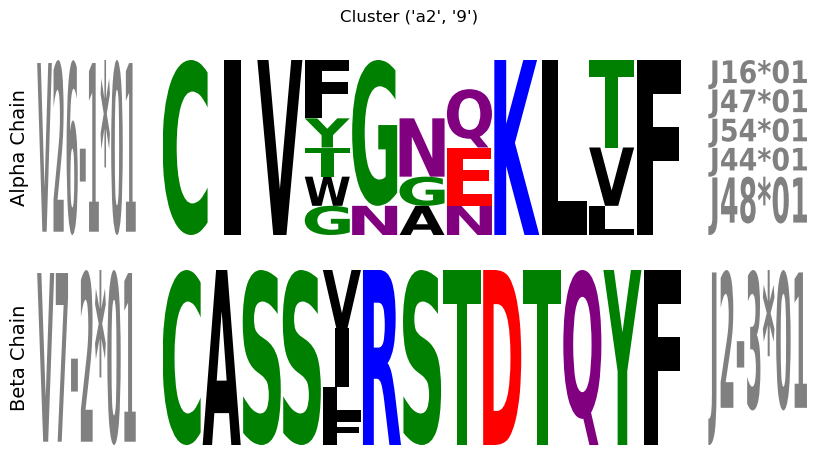

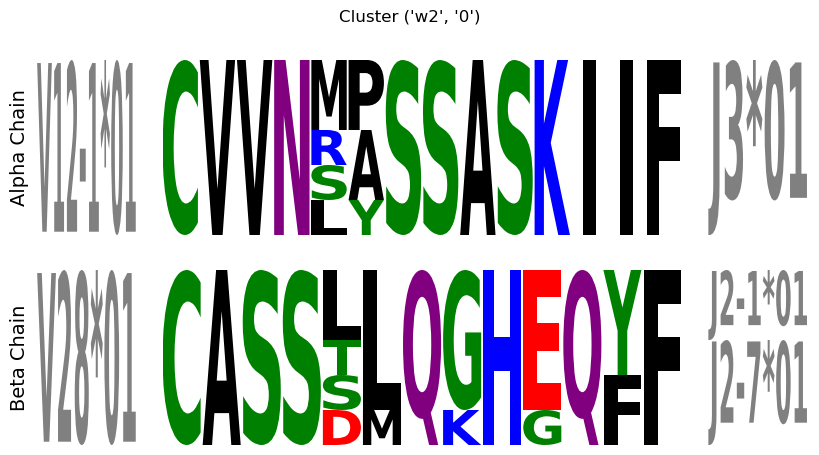

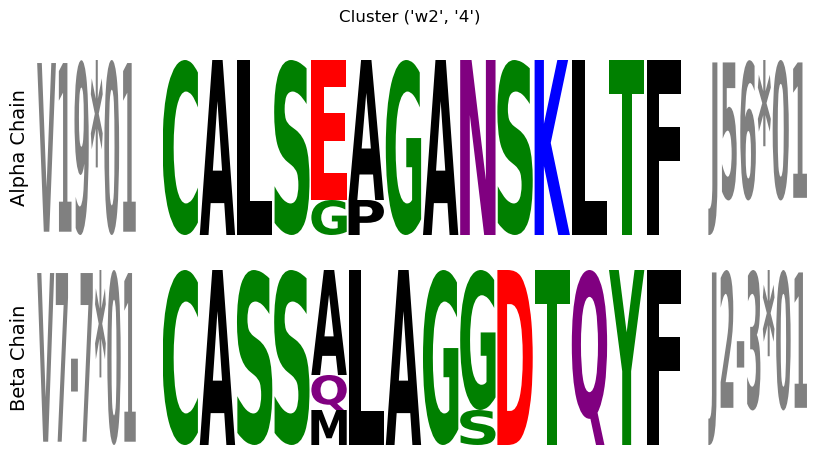

In [9]:
(
    coeliac_sequences.query("cluster != 'None'")
    .groupby(['pmhc_calls', 'cluster'])
    .apply(make_logo_plot, include_groups=False)
)